# NSL-KDD Intrusion Detection — Model Training

Binary classification (**Normal vs Attack**) on the NSL-KDD dataset with five
models: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes and SVM.

Pipeline: load -> clean -> stratified split -> encode/scale -> train -> evaluate -> save.

## 1. Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.evaluate import (
    compute_metrics, evaluate_models, get_classification_report,
    get_confusion_matrix, get_roc_curve, predict_with_scores,
)
from src.preprocessing import (
    clean_dataset, fit_preprocessor, make_binary_target, split_data,
    transform_features,
)
from src.train_models import build_models, export_test_data, save_models, train_models
from src.utils import CATEGORICAL_COLUMNS, LABEL_COLUMN, METRICS_PATH, load_raw_dataset

sns.set_theme(style="whitegrid")

## 2. Load dataset

In [2]:
raw = load_raw_dataset()   # downloads KDDTrain+.txt into data/ if missing
print("Shape:", raw.shape)
raw.head()

Shape: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
print("Records :", len(raw))
print("Features:", raw.shape[1] - 2, "(excluding label and difficulty)")
raw[CATEGORICAL_COLUMNS].nunique()

Records : 125973
Features: 41 (excluding label and difficulty)


protocol_type     3
service          70
flag             11
dtype: int64

## 3. Cleaning: missing values and duplicates

In [4]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.drop(columns=["difficulty"]).duplicated().sum()))
df = clean_dataset(raw)
print("Shape after cleaning:", df.shape)

Missing values: 0


Duplicate rows: 0


2026-11-07 17:27:56,070 | INFO | src.preprocessing | Missing values before cleaning: 0


2026-11-07 17:27:56,188 | INFO | src.preprocessing | Removed 0 duplicate/unlabeled rows


Shape after cleaning: (125973, 42)


## 4. Target distribution (Normal = 0, Attack = 1)

label
Normal    67343
Attack    58630
Name: count, dtype: int64


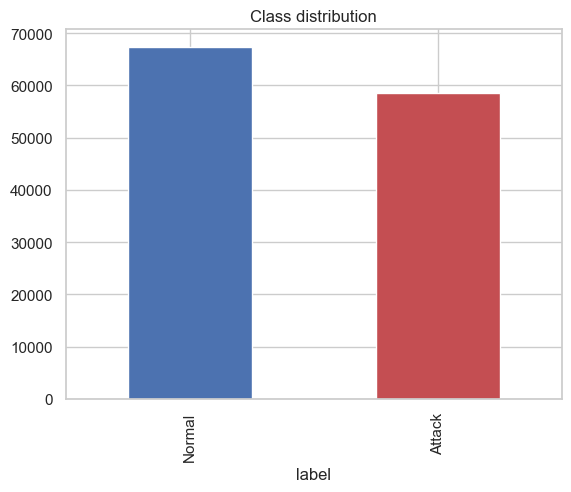

In [5]:
target = make_binary_target(df[LABEL_COLUMN])
print(target.value_counts().rename({0: "Normal", 1: "Attack"}))
ax = target.map({0: "Normal", 1: "Attack"}).value_counts().plot(kind="bar", color=["#4c72b0", "#c44e52"])
ax.set_title("Class distribution")
plt.show()

## 5. Stratified train/test split (80/20, `random_state=42`)

In [6]:
train_df, test_df = split_data(df)
y_train = make_binary_target(train_df[LABEL_COLUMN])
y_test = make_binary_target(test_df[LABEL_COLUMN])
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Attack ratio train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

Train: (100778, 42) | Test: (25195, 42)
Attack ratio train/test: 0.4654 0.4654


## 6. Label encoding + StandardScaler (fitted on the training split only)

In [7]:
preprocessor = fit_preprocessor(train_df)
X_train = transform_features(train_df, preprocessor)
X_test = transform_features(test_df, preprocessor)
for col, enc in preprocessor["encoders"].items():
    print(f"{col}: {len(enc.classes_)} categories")
X_train.describe().T.head(8)

protocol_type: 3 categories
service: 69 categories
flag: 11 categories


,count,mean,std,min,25%,50%,75%,max
duration,100778.0,1.128092e-17,1.000005,-0.110764,-0.110764,-0.110764,-0.110764,16.310412
protocol_type,100778.0,1.703419e-16,1.000005,-2.468954,-0.123998,-0.123998,-0.123998,2.220958
service,100778.0,-3.948321e-18,1.000005,-1.936321,-0.679019,-0.427559,1.081204,2.338506
flag,100778.0,-2.453600e-17,1.000005,-2.593536,-0.734739,0.752298,0.752298,1.124058
src_bytes,100778.0,1.128092e-18,1.000005,-0.007441,-0.007441,-0.007433,-0.007390,256.263856
dst_bytes,100778.0,5.640459e-19,1.000005,-0.005284,-0.005284,-0.005284,-0.005170,291.374761
land,100778.0,2.679218e-18,1.000005,-0.014089,-0.014089,-0.014089,-0.014089,70.978166
wrong_fragment,100778.0,1.960060e-17,1.000005,-0.088318,-0.088318,-0.088318,-0.088318,11.912395


## 7. Train all five models

In [8]:
models = train_models(build_models(), X_train, y_train)

2026-11-07 17:27:57,866 | INFO | src.train_models | Trained Logistic Regression  in 0.8s


2026-11-07 17:27:58,976 | INFO | src.train_models | Trained Decision Tree        in 1.1s


2026-11-07 17:27:58,999 | INFO | src.train_models | Trained KNN                  in 0.0s


2026-11-07 17:27:59,101 | INFO | src.train_models | Trained Naive Bayes          in 0.1s


2026-11-07 17:28:46,492 | INFO | src.train_models | Trained SVM                  in 47.4s


## 8. Evaluation

In [9]:
results = evaluate_models(models, X_test, y_test)
results.round(4)

,ML Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9519,0.9921,0.9585,0.9371,0.9477,0.9033
1,Decision Tree,0.9977,0.9978,0.9979,0.9973,0.9976,0.9955
2,KNN,0.9960,0.9994,0.9962,0.9952,0.9957,0.9919
3,Naive Bayes,0.8946,0.9509,0.8655,0.9159,0.8900,0.7902
4,SVM,0.9922,0.9994,0.9931,0.9902,0.9916,0.9844


In [10]:
for name, model in models.items():
    y_pred, _ = predict_with_scores(model, X_test)
    print(f"\n=== {name} ===")
    print(get_classification_report(y_test, y_pred).round(4))


=== Logistic Regression ===
              precision  recall  f1-score  support
Normal           0.9463  0.9647    0.9554    13469
Attack           0.9585  0.9371    0.9477    11726
accuracy         0.9519  0.9519    0.9519        0
macro avg        0.9524  0.9509    0.9515    25195
weighted avg     0.9520  0.9519    0.9518    25195

=== Decision Tree ===
              precision  recall  f1-score  support
Normal           0.9976  0.9981    0.9979    13469
Attack           0.9979  0.9973    0.9976    11726
accuracy         0.9977  0.9977    0.9977        0
macro avg        0.9977  0.9977    0.9977    25195
weighted avg     0.9977  0.9977    0.9977    25195



=== KNN ===
              precision  recall  f1-score  support
Normal           0.9958  0.9967    0.9963    13469
Attack           0.9962  0.9952    0.9957    11726
accuracy         0.9960  0.9960    0.9960        0
macro avg        0.9960  0.9959    0.9960    25195
weighted avg     0.9960  0.9960    0.9960    25195

=== Naive Bayes ===
              precision  recall  f1-score  support
Normal           0.9229  0.8761    0.8989    13469
Attack           0.8655  0.9159    0.8900    11726
accuracy         0.8946  0.8946    0.8946        0
macro avg        0.8942  0.8960    0.8944    25195
weighted avg     0.8962  0.8946    0.8947    25195



=== SVM ===
              precision  recall  f1-score  support
Normal           0.9915  0.9940    0.9927    13469
Attack           0.9931  0.9902    0.9916    11726
accuracy         0.9922  0.9922    0.9922        0
macro avg        0.9923  0.9921    0.9922    25195
weighted avg     0.9922  0.9922    0.9922    25195


## 9. Visualisations

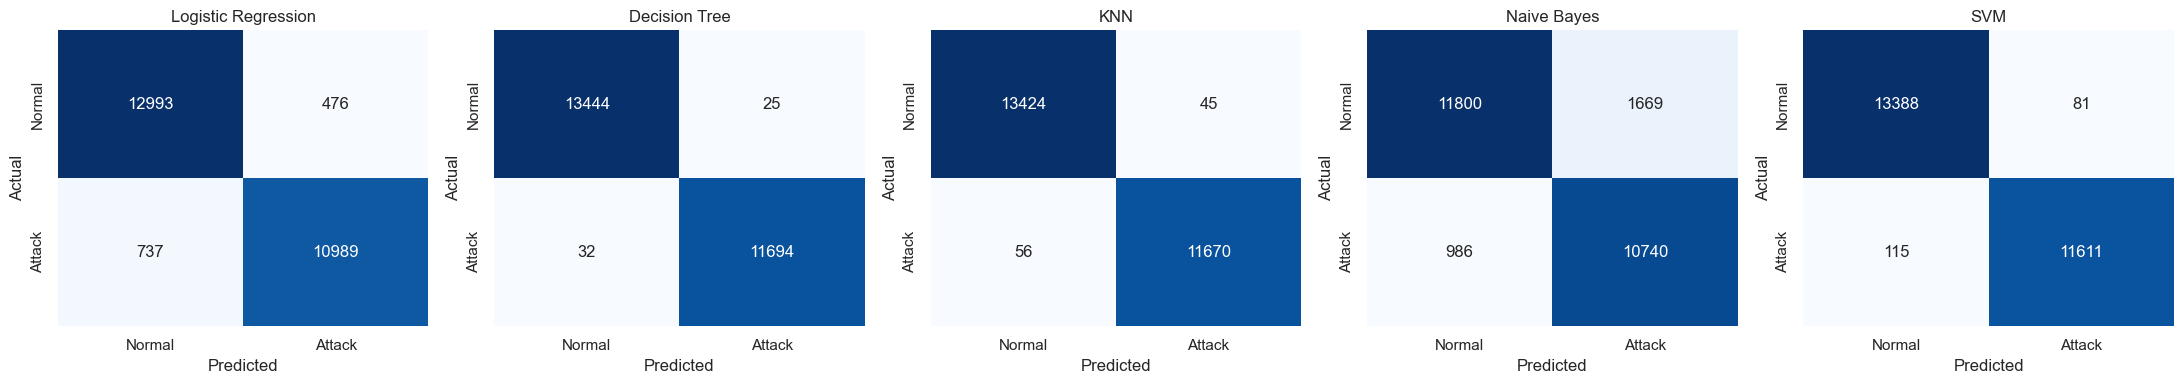

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    y_pred, _ = predict_with_scores(model, X_test)
    sns.heatmap(get_confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"],
                cbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

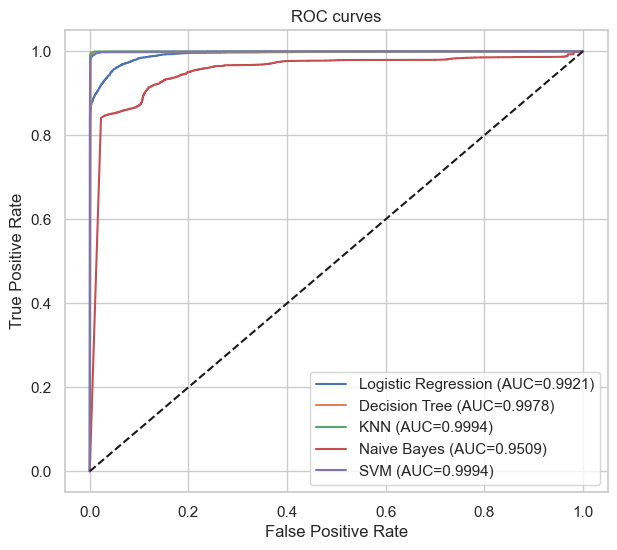

In [12]:
plt.figure(figsize=(7, 6))
for name, model in models.items():
    _, score = predict_with_scores(model, X_test)
    fpr, tpr = get_roc_curve(y_test, score)
    auc = compute_metrics(y_test, model.predict(X_test), score)["AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves"); plt.legend(); plt.show()

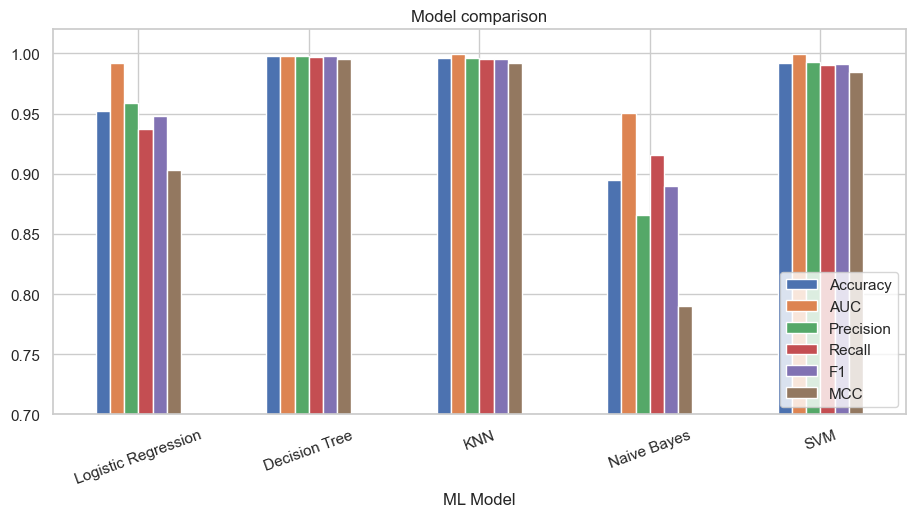

In [13]:
results.set_index("ML Model").plot(kind="bar", figsize=(11, 5), ylim=(0.7, 1.02))
plt.title("Model comparison"); plt.xticks(rotation=20); plt.legend(loc="lower right"); plt.show()

## 10. Save models, metrics and the test set

In [14]:
save_models(models, preprocessor)          # model/*.pkl + model/preprocessor.pkl
results.to_csv(METRICS_PATH, index=False)
export_test_data(test_df)                  # test_data.csv for the Streamlit app

2026-11-07 17:30:41,533 | INFO | src.train_models | Saved Logistic Regression -> model/logistic_regression.pkl


2026-11-07 17:30:41,541 | INFO | src.train_models | Saved Decision Tree -> model/decision_tree.pkl


2026-11-07 17:30:41,890 | INFO | src.train_models | Saved KNN -> model/knn.pkl


2026-11-07 17:30:41,894 | INFO | src.train_models | Saved Naive Bayes -> model/naive_bayes.pkl


2026-11-07 17:30:41,922 | INFO | src.train_models | Saved SVM -> model/svm.pkl


2026-11-07 17:30:42,465 | INFO | src.train_models | Exported 25195 rows to test_data.csv


## 11. Best model

In [15]:
best = results.sort_values(["MCC", "F1"], ascending=False).iloc[0]
print(f"Best model: {best['ML Model']} (MCC={best['MCC']:.4f}, F1={best['F1']:.4f})")

Best model: Decision Tree (MCC=0.9955, F1=0.9976)
